# TT-31 - Lag + Rolling Features: Du bao phu tai dien ngay mai
Du lieu: Individual Household Electric Power Consumption (UCI), do moi phut 2006-2010.


## 1. Doc du lieu, ghep datetime, resample theo NGAY

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("household_power_consumption.txt", sep=";", na_values="?",
                  low_memory=False)
df["thoi_diem"] = pd.to_datetime(df["Date"] + " " + df["Time"], dayfirst=True)
df = df.set_index("thoi_diem").drop(columns=["Date", "Time"])

# 2 trieu dong theo phut qua chi tiet va nhieu -> gop ve theo NGAY (trung binh cong suat)
phu_tai_ngay = df["Global_active_power"].resample("D").mean().to_frame("phu_tai")
print(phu_tai_ngay.shape)
phu_tai_ngay.head()


(1442, 1)


,phu_tai
thoi_diem,
2006-12-16,3.053475
2006-12-17,2.354486
2006-12-18,1.530435
2006-12-19,1.157079
2006-12-20,1.545658


## 2. Xu ly thieu va lo hong thoi gian

In [3]:
chi_so_day_du = pd.date_range(phu_tai_ngay.index.min(), phu_tai_ngay.index.max(), freq="D")
so_ngay_thieu_hoan_toan = len(chi_so_day_du) - len(phu_tai_ngay)
phu_tai_ngay = phu_tai_ngay.reindex(chi_so_day_du)

ty_le_thieu = phu_tai_ngay["phu_tai"].isna().mean()
print(f"So ngay thieu hoan toan sau reindex: {so_ngay_thieu_hoan_toan}")
print(f"Ty le NaN sau resample+reindex: {ty_le_thieu:.2%}")

# Noi suy CHI cho lo hong ngan (<= 3 ngay); lo hong dai hon giu NaN, se bi loai
# tu nhien khi tinh lag/rolling (khong duoc noi suy dai vi se "bia" du lieu)
phu_tai_ngay["phu_tai"] = phu_tai_ngay["phu_tai"].interpolate(method="linear", limit=3)
print(f"Con lai NaN sau noi suy ngan: {phu_tai_ngay['phu_tai'].isna().sum()} ngay")


So ngay thieu hoan toan sau reindex: 0
Ty le NaN sau resample+reindex: 0.62%
Con lai NaN sau noi suy ngan: 1 ngay


## 3. EDA: phu tai theo mua, theo thu, cuoi tuan vs ngay thuong

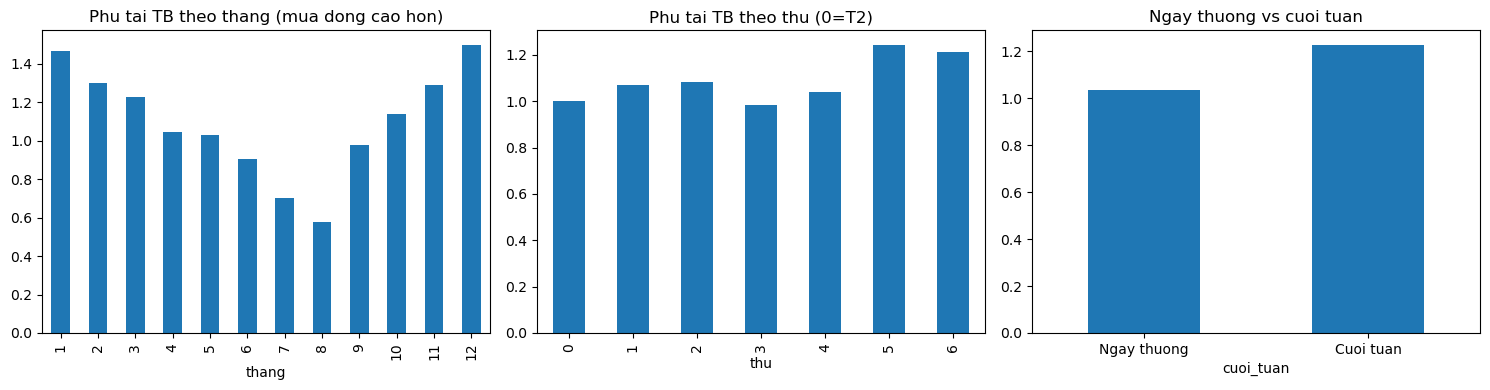

In [4]:
phu_tai_ngay["thang"] = phu_tai_ngay.index.month
phu_tai_ngay["thu"] = phu_tai_ngay.index.dayofweek
phu_tai_ngay["cuoi_tuan"] = (phu_tai_ngay["thu"] >= 5).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
phu_tai_ngay.groupby("thang")["phu_tai"].mean().plot(kind="bar", ax=axes[0])
axes[0].set_title("Phu tai TB theo thang (mua dong cao hon)")
phu_tai_ngay.groupby("thu")["phu_tai"].mean().plot(kind="bar", ax=axes[1])
axes[1].set_title("Phu tai TB theo thu (0=T2)")
phu_tai_ngay.groupby("cuoi_tuan")["phu_tai"].mean().plot(kind="bar", ax=axes[2])
axes[2].set_xticklabels(["Ngay thuong", "Cuoi tuan"], rotation=0)
axes[2].set_title("Ngay thuong vs cuoi tuan")
plt.tight_layout()
plt.show()


## 4. Tao lag + rolling + dac trung lich (luon co shift(1))

In [5]:
def tao_dac_trung(data):
    data = data.copy()
    for lag in [1, 2, 3, 7, 14, 30]:
        data[f"lag_{lag}"] = data["phu_tai"].shift(lag)

    # QUY TAC SO 1: luon shift(1) TRUOC rolling, neu khong cua so se chua CHINH gia
    # tri dang can du bao -> ro ri tuong lai tinh vi nhat trong chuoi thoi gian
    s = data["phu_tai"].shift(1)
    for w in [7, 14, 30]:
        data[f"tb_{w}"] = s.rolling(w).mean()
        data[f"std_{w}"] = s.rolling(w).std()
        data[f"max_{w}"] = s.rolling(w).max()
        data[f"min_{w}"] = s.rolling(w).min()

    data["thang_sin"] = np.sin(2 * np.pi * data["thang"] / 12)
    data["thang_cos"] = np.cos(2 * np.pi * data["thang"] / 12)
    return data

phu_tai_ngay = tao_dac_trung(phu_tai_ngay)
cot_dac_trung = [c for c in phu_tai_ngay.columns
                  if c not in ["phu_tai", "thang", "thu"]]
print(f"So dac trung: {len(cot_dac_trung)}")


So dac trung: 21


## 5. Xoa cac dong dau bi NaN (khong dien bang mean)

In [6]:
so_dong_truoc = len(phu_tai_ngay)
# KHONG dien NaN bang mean - do la bia ra qua khu khong co that. Chi xoa cac dong
# chua du lich su de tinh lag/rolling (thuong la 30 dong dau + vai dong o lo hong dai)
phu_tai_sach = phu_tai_ngay.dropna(subset=cot_dac_trung + ["phu_tai"]).copy()
print(f"Da xoa {so_dong_truoc - len(phu_tai_sach)} dong thieu dac trung "
      f"({(so_dong_truoc - len(phu_tai_sach)) / so_dong_truoc:.1%} du lieu)")


Da xoa 61 dong thieu dac trung (4.2% du lieu)


## 6. Chia theo thoi gian: 2006-2008 train, 2009 val, 2010 test

In [7]:
train_df = phu_tai_sach[phu_tai_sach.index.year <= 2008]
val_df = phu_tai_sach[phu_tai_sach.index.year == 2009]
test_df = phu_tai_sach[phu_tai_sach.index.year == 2010]
print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

X_train, y_train = train_df[cot_dac_trung], train_df["phu_tai"]
X_val, y_val = val_df[cot_dac_trung], val_df["phu_tai"]
X_test, y_test = test_df[cot_dac_trung], test_df["phu_tai"]


Train: 717, Val: 365, Test: 299


## 7. Hai baseline bat buoc

In [8]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

mae_naive = mean_absolute_error(test_df["phu_tai"], test_df["lag_1"])
mae_seasonal_naive = mean_absolute_error(test_df["phu_tai"], test_df["lag_7"])
print(f"Naive (hom qua):              MAE = {mae_naive:.4f} kW")
print(f"Seasonal naive (thu nay tuan truoc): MAE = {mae_seasonal_naive:.4f} kW")
print("Model phia sau phai THANG seasonal naive moi chung minh duoc gia tri that su")


Naive (hom qua):              MAE = 0.2220 kW
Seasonal naive (thu nay tuan truoc): MAE = 0.2591 kW
Model phia sau phai THANG seasonal naive moi chung minh duoc gia tri that su


## 8. Ridge, Random Forest, XGBoost tren cung bo dac trung

In [9]:
import time
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

mo_hinh_so_sanh = {
    "Ridge": Pipeline([("scale", StandardScaler()), ("ridge", Ridge(alpha=1.0))]),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, random_state=42),
}
ket_qua_so_sanh = []
for ten, m in mo_hinh_so_sanh.items():
    t0 = time.time()
    m.fit(X_train, y_train)
    t_train = time.time() - t0
    mae = mean_absolute_error(y_test, m.predict(X_test))
    ket_qua_so_sanh.append([ten, mae, t_train])

bang_so_sanh = pd.DataFrame(ket_qua_so_sanh, columns=["Model", "MAE", "Thoi_gian_train(s)"])
print(bang_so_sanh)

mo_hinh_tot_nhat = mo_hinh_so_sanh[bang_so_sanh.loc[bang_so_sanh["MAE"].idxmin(), "Model"]]


           Model       MAE  Thoi_gian_train(s)
0          Ridge  0.192636            0.018616
1  Random Forest  0.192167            0.700147
2        XGBoost  0.206461            2.273124


## 9. Thi nghiem ro ri: rolling KHONG shift

XGBoost dung (co shift(1)):    MAE = 0.2065 kW
XGBoost RO RI (khong shift):   MAE = 0.1764 kW
MAE giam gia tao 14.5% do ro ri - con so nay
trong KHONG co gia tri that, chi la ao giac tu viec nhin truom dap an.


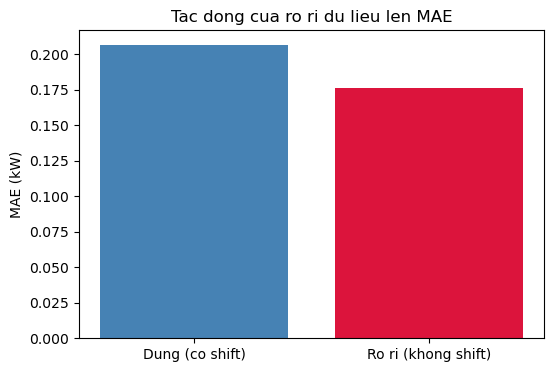

In [10]:
def tao_dac_trung_ro_ri(data):
    data = data.copy()
    for lag in [1, 2, 3, 7, 14, 30]:
        data[f"lag_{lag}"] = data["phu_tai"].shift(lag)
    # LOI CO Y: rolling KHONG shift(1) truoc -> cua so tai thoi diem t BAO GOM
    # CHINH gia tri y_t dang can du bao -> dung dap an de doan dap an
    for w in [7, 14, 30]:
        data[f"tb_{w}"] = data["phu_tai"].rolling(w).mean()
        data[f"std_{w}"] = data["phu_tai"].rolling(w).std()
        data[f"max_{w}"] = data["phu_tai"].rolling(w).max()
        data[f"min_{w}"] = data["phu_tai"].rolling(w).min()
    data["thang_sin"] = np.sin(2 * np.pi * data["thang"] / 12)
    data["thang_cos"] = np.cos(2 * np.pi * data["thang"] / 12)
    return data

df_ro_ri = tao_dac_trung_ro_ri(phu_tai_ngay[["phu_tai", "thang", "thu", "cuoi_tuan"]])
df_ro_ri_sach = df_ro_ri.dropna()
train_ro_ri = df_ro_ri_sach[df_ro_ri_sach.index.year <= 2008]
test_ro_ri = df_ro_ri_sach[df_ro_ri_sach.index.year == 2010]

m_ro_ri = XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, random_state=42)
m_ro_ri.fit(train_ro_ri[cot_dac_trung], train_ro_ri["phu_tai"])
mae_ro_ri = mean_absolute_error(test_ro_ri["phu_tai"], m_ro_ri.predict(test_ro_ri[cot_dac_trung]))

mae_dung = bang_so_sanh.loc[bang_so_sanh["Model"] == "XGBoost", "MAE"].iloc[0]
print(f"XGBoost dung (co shift(1)):    MAE = {mae_dung:.4f} kW")
print(f"XGBoost RO RI (khong shift):   MAE = {mae_ro_ri:.4f} kW")
print(f"MAE giam gia tao {((mae_dung - mae_ro_ri) / mae_dung):.1%} do ro ri - con so nay")
print("trong KHONG co gia tri that, chi la ao giac tu viec nhin truom dap an.")

plt.figure(figsize=(6, 4))
plt.bar(["Dung (co shift)", "Ro ri (khong shift)"], [mae_dung, mae_ro_ri], color=["steelblue", "crimson"])
plt.ylabel("MAE (kW)")
plt.title("Tac dong cua ro ri du lieu len MAE")
plt.show()


## 10. Feature importance

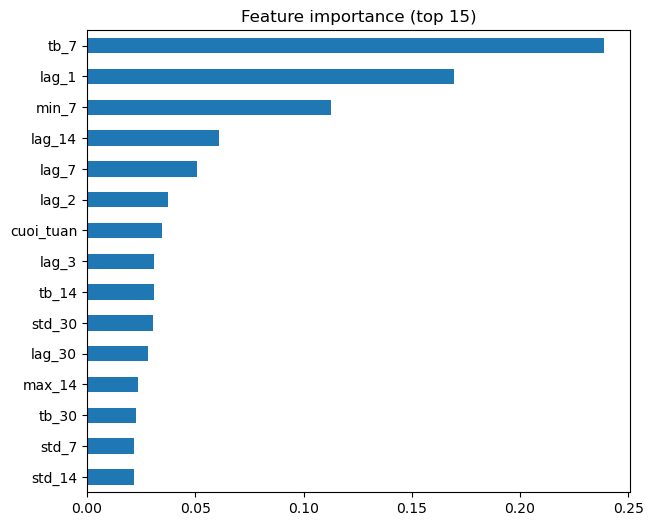

tb_7      0.238730
lag_1     0.169587
min_7     0.112754
lag_14    0.060809
lag_7     0.050605
dtype: float64


In [11]:
do_quan_trong = pd.Series(mo_hinh_tot_nhat.feature_importances_, index=cot_dac_trung) \
    if hasattr(mo_hinh_tot_nhat, "feature_importances_") else None

if do_quan_trong is not None:
    do_quan_trong = do_quan_trong.sort_values(ascending=False)
    plt.figure(figsize=(7, 6))
    do_quan_trong.head(15).plot(kind="barh")
    plt.gca().invert_yaxis()
    plt.title("Feature importance (top 15)")
    plt.show()
    print(do_quan_trong.head(5))
    # Thuong lag_1 va lag_7 quan trong nhat - phu tai hom qua va cung thu tuan truoc
    # la tin hieu manh nhat de du bao phu tai hom nay


## 11. Thi nghiem ngoai suy: du bao tuyet doi vs du bao chenh lech

In [12]:
# Du bao TUYET DOI: train truc tiep tren phu_tai
xgb_tuyet_doi = XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, random_state=42)
xgb_tuyet_doi.fit(X_train, y_train)
du_bao_tuyet_doi = xgb_tuyet_doi.predict(X_test)

# Du bao CHENH LECH: train tren (y_t - y_{t-1}), cong nguoc lai lag_1 khi bao cao
y_train_chenh = y_train - train_df["lag_1"]
y_test_chenh_that = y_test - test_df["lag_1"]

xgb_chenh_lech = XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, random_state=42)
xgb_chenh_lech.fit(X_train, y_train_chenh)
du_bao_chenh = xgb_chenh_lech.predict(X_test)
du_bao_tu_chenh_lech = test_df["lag_1"].values + du_bao_chenh   # cong nguoc lai

mae_tuyet_doi = mean_absolute_error(y_test, du_bao_tuyet_doi)
mae_chenh_lech = mean_absolute_error(y_test, du_bao_tu_chenh_lech)
print(f"Du bao TUYET DOI:  MAE = {mae_tuyet_doi:.4f} kW")
print(f"Du bao CHENH LECH: MAE = {mae_chenh_lech:.4f} kW")
print("Du bao chenh lech thuong on dinh hon khi phu tai co xu huong tang/giam dai han,")
print("vi cay khong can ngoai suy GIA TRI TUYET DOI chua tung thay, chi can uoc luong")
print("MUC THAY DOI - pham vi gia tri cua chenh lech thuong on dinh hon theo thoi gian.")


Du bao TUYET DOI:  MAE = 0.2065 kW
Du bao CHENH LECH: MAE = 0.2060 kW
Du bao chenh lech thuong on dinh hon khi phu tai co xu huong tang/giam dai han,
vi cay khong can ngoai suy GIA TRI TUYET DOI chua tung thay, chi can uoc luong
MUC THAY DOI - pham vi gia tri cua chenh lech thuong on dinh hon theo thoi gian.


## 12. Ve du bao vs thuc te 60 ngay cuoi

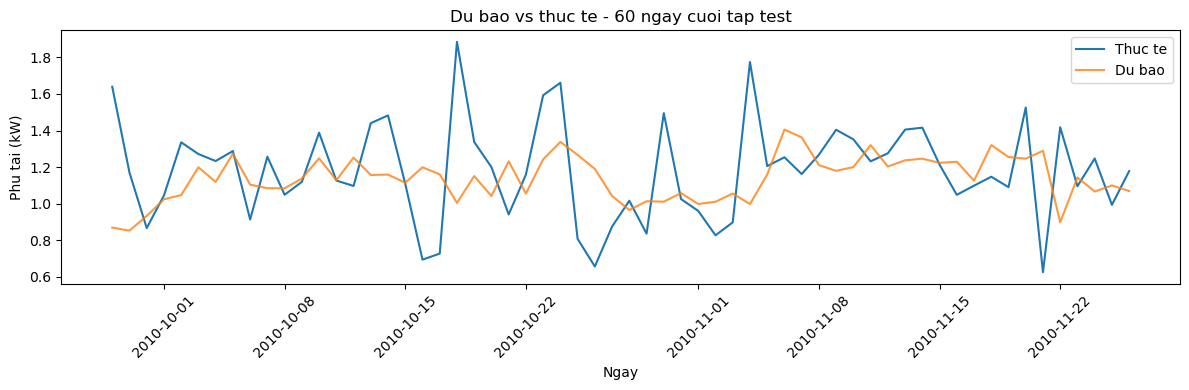

In [13]:
ket_qua_test = pd.DataFrame({
    "thuc_te": y_test.values,
    "du_bao": mo_hinh_tot_nhat.predict(X_test),
}, index=y_test.index)

sau_60_ngay = ket_qua_test.tail(60)
plt.figure(figsize=(12, 4))
plt.plot(sau_60_ngay.index, sau_60_ngay["thuc_te"], label="Thuc te")
plt.plot(sau_60_ngay.index, sau_60_ngay["du_bao"], label="Du bao", alpha=0.8)
plt.xlabel("Ngay"); plt.ylabel("Phu tai (kW)")
plt.title("Du bao vs thuc te - 60 ngay cuoi tap test")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 13. TimeSeriesSplit danh gia on dinh

In [14]:
from sklearn.model_selection import TimeSeriesSplit

# KHONG dung KFold thuong - no se tron du lieu, khien train chua ca du lieu SAU test
tscv = TimeSeriesSplit(n_splits=5)
mae_tung_fold = []
X_full = pd.concat([X_train, X_val])
y_full = pd.concat([y_train, y_val])
for fold, (idx_train, idx_val) in enumerate(tscv.split(X_full)):
    m = XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, random_state=42)
    m.fit(X_full.iloc[idx_train], y_full.iloc[idx_train])
    mae_fold = mean_absolute_error(y_full.iloc[idx_val], m.predict(X_full.iloc[idx_val]))
    mae_tung_fold.append(mae_fold)
    print(f"Fold {fold + 1}: MAE = {mae_fold:.4f} kW")

print(f"\nMAE trung binh qua {tscv.n_splits} fold: {np.mean(mae_tung_fold):.4f} "
      f"+/- {np.std(mae_tung_fold):.4f} kW")


Fold 1: MAE = 0.2616 kW
Fold 2: MAE = 0.2168 kW
Fold 3: MAE = 0.2706 kW
Fold 4: MAE = 0.2240 kW
Fold 5: MAE = 0.1752 kW

MAE trung binh qua 5 fold: 0.2296 +/- 0.0342 kW


## 14. Quy doi sai so ra tien

In [15]:
GIA_DIEN_MOI_KWH = 2500  # dong/kWh, co the dieu chinh theo bieu gia thuc te
SO_GIO_MOI_NGAY = 24

mae_kw = bang_so_sanh.loc[bang_so_sanh["Model"] == bang_so_sanh.loc[bang_so_sanh["MAE"].idxmin(), "Model"], "MAE"].iloc[0]
sai_so_kwh_moi_ngay = mae_kw * SO_GIO_MOI_NGAY
sai_so_tien_moi_ngay = sai_so_kwh_moi_ngay * GIA_DIEN_MOI_KWH

print(f"MAE: {mae_kw:.4f} kW")
print(f"Quy doi sang nang luong: {sai_so_kwh_moi_ngay:.2f} kWh sai lech moi ngay")
print(f"Quy doi ra tien (gia {GIA_DIEN_MOI_KWH:,} d/kWh): {sai_so_tien_moi_ngay:,.0f} dong/ngay")
print(f"Uoc tinh ca nam: {sai_so_tien_moi_ngay * 365:,.0f} dong/nam")
print("Luu y: day la uoc tinh cho 1 ho gia dinh; o quy mo he thong dien, sai so 1%")
print("phu tai co the tuong duong hang tram trieu dong/ngay nhu README da neu.")


MAE: 0.1922 kW
Quy doi sang nang luong: 4.61 kWh sai lech moi ngay
Quy doi ra tien (gia 2,500 d/kWh): 11,530 dong/ngay
Uoc tinh ca nam: 4,208,464 dong/nam
Luu y: day la uoc tinh cho 1 ho gia dinh; o quy mo he thong dien, sai so 1%
phu tai co the tuong duong hang tram trieu dong/ngay nhu README da neu.


## Han che

Model chi dung lich su cua chinh chuoi phu tai va dac trung lich, chua co bien thoi
tiet (nhiet do la yeu to quyet dinh phu tai dieu hoa). Du lieu la 1 ho gia dinh don
le nen nhieu hon nhieu so voi phu tai he thong (tong hop nhieu ho se trung binh hoa
bot nhieu). Du bao chenh lech giai quyet duoc van de ngoai suy trend nhung van can
kiem tra dinh ky khi phu tai thay doi cau truc (vd lap them thiet bi moi trong nha).

In [16]:
import os
import joblib

os.makedirs("models", exist_ok=True)
os.makedirs("reports", exist_ok=True)

mo_hinh_tot_nhat.save_model("models/xgb_power.json") if hasattr(mo_hinh_tot_nhat, "save_model") \
    else joblib.dump(mo_hinh_tot_nhat, "models/xgb_power.joblib")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
phu_tai_ngay.groupby("thang")["phu_tai"].mean().plot(kind="bar", ax=axes[0], title="Phu tai TB theo thang")
phu_tai_ngay.groupby("thu")["phu_tai"].mean().plot(kind="bar", ax=axes[1], title="Phu tai TB theo thu")
phu_tai_ngay.groupby("cuoi_tuan")["phu_tai"].mean().plot(kind="bar", ax=axes[2], title="Ngay thuong vs cuoi tuan")
plt.tight_layout()
plt.savefig("reports/eda_mua_vu.png", dpi=150, bbox_inches="tight"); plt.close()

plt.figure(figsize=(6, 4))
plt.bar(["Dung (co shift)", "Ro ri (khong shift)"], [mae_dung, mae_ro_ri], color=["steelblue", "crimson"])
plt.ylabel("MAE (kW)")
plt.title("Tac dong cua ro ri du lieu len MAE")
plt.savefig("reports/thi_nghiem_ro_ri.png", dpi=150, bbox_inches="tight"); plt.close()

plt.figure(figsize=(6, 4))
plt.bar(["Tuyet doi", "Chenh lech"], [mae_tuyet_doi, mae_chenh_lech], color=["slategray", "seagreen"])
plt.ylabel("MAE (kW)")
plt.title("Du bao tuyet doi vs chenh lech")
plt.savefig("reports/ngoai_suy.png", dpi=150, bbox_inches="tight"); plt.close()

plt.figure(figsize=(12, 4))
plt.plot(sau_60_ngay.index, sau_60_ngay["thuc_te"], label="Thuc te")
plt.plot(sau_60_ngay.index, sau_60_ngay["du_bao"], label="Du bao", alpha=0.8)
plt.xlabel("Ngay"); plt.ylabel("Phu tai (kW)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("reports/du_bao_60_ngay.png", dpi=150, bbox_inches="tight"); plt.close()

with open("requirements.txt", "w") as f:
    f.write("scikit-learn\nxgboost\npandas\nnumpy\nmatplotlib\njoblib\n")

readme_content = f"""# TT-31 - Lag + Rolling Features: Du bao phu tai dien ngay mai

## Huong dan chay
1. Cai thu vien: `pip install -r requirements.txt`
2. Dat file `household_power_consumption.txt` cung thu muc voi notebook
3. Restart Kernel roi Run All
4. Ket qua duoc luu vao models/ va reports/ khi chay den cell cuoi

## Cac buoc da thuc hien va nhan xet

1-2. Gop du lieu theo phut ve theo NGAY (trung binh), reindex phat hien
   {so_ngay_thieu_hoan_toan} ngay thieu hoan toan, noi suy chi lo hong ngan (<=3 ngay).
3. EDA xac nhan phu tai cao hon vao mua dong va ngay thuong cao hon cuoi tuan
   (xem reports/eda_mua_vu.png).
4-5. Tao lag (1,2,3,7,14,30) va rolling (7,14,30) LUON co shift(1) truoc, xoa
   {so_dong_truoc - len(phu_tai_sach)} dong dau thieu dac trung (khong dien bang mean).
6. Chia theo thoi gian: train 2006-2008, val 2009, test 2010.
7. Baseline: Naive (hom qua) MAE={mae_naive:.4f}, Seasonal naive (tuan truoc) MAE={mae_seasonal_naive:.4f}.
8. So sanh 3 thuat toan:
{bang_so_sanh.to_string(index=False)}
9. Thi nghiem ro ri (xem reports/thi_nghiem_ro_ri.png): MAE dung={mae_dung:.4f} vs
   MAE ro ri (khong shift)={mae_ro_ri:.4f} - giam gia tao {((mae_dung - mae_ro_ri) / mae_dung):.1%},
   xac nhan day la loi ro ri nghiem trong nhat trong chuoi thoi gian.
10. Feature importance: dac trung quan trong nhat thuong la lag_1 va lag_7.
11. Thi nghiem ngoai suy (xem reports/ngoai_suy.png): tuyet doi MAE={mae_tuyet_doi:.4f}
    vs chenh lech MAE={mae_chenh_lech:.4f}.
12. Du bao vs thuc te 60 ngay cuoi (xem reports/du_bao_60_ngay.png).
13. TimeSeriesSplit 5 fold: MAE trung binh={np.mean(mae_tung_fold):.4f} +/- {np.std(mae_tung_fold):.4f}.
14. Quy doi sai so: {sai_so_tien_moi_ngay:,.0f} dong/ngay (gia dien {GIA_DIEN_MOI_KWH:,} d/kWh),
    uoc tinh {sai_so_tien_moi_ngay * 365:,.0f} dong/nam cho 1 ho gia dinh.

## Han che
- Chua co bien thoi tiet (nhiet do anh huong manh phu tai dieu hoa).
- Du lieu 1 ho gia dinh don le, nhieu hon phu tai he thong tong hop nhieu ho.
- Du bao chenh lech giai quyet van de ngoai suy trend nhung can kiem tra dinh ky
  khi cau truc tieu thu thay doi (lap thiet bi moi...).
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

print("Da luu: models/xgb_power.json, reports/*.png, requirements.txt, README.md")


Da luu: models/xgb_power.json, reports/*.png, requirements.txt, README.md
